# DWD-Wetterdaten: Berlin 2020 bis heute

Dieses Notebook lädt und prüft die vorbereitete CSV-Datei der DWD-Station **Berlin-Dahlem (FU), Stations-ID 00403**. Es visualisiert Temperaturverläufe und saisonale Temperaturspannen und erstellt eine Ein-Tages-Prognose der Tagesmitteltemperatur mit einem neuronalen Regressionsmodell. Die Modellgüte wird auf späteren, beim Training nicht verwendeten Daten getestet. Die CSV deckt den Zeitraum **01.01.2020 bis 01.11.2026** ab, dem neuesten verfügbaren DWD-Datum zum Download.

## Datenquelle und Station

Die CSV wurde aus den historischen und aktuellen Tageswerten des **DWD Climate Data Center (CDC)** zusammengeführt. Berlin-Dahlem liegt bei 52.4537° N, 13.3017° E. Die Sonnenscheindauer ist im DWD-Feld `SDK` in Stunden erfasst. Temperaturen stehen in °C, Niederschlag in mm.

Berlin-Tempelhof (00433) wurde nicht verwendet: Dort endet die Sonnenscheindauer-Reihe bereits 2022. Berlin-Dahlem liefert alle fünf gewünschten Merkmale bis zum aktuellen Archivstand, allerdings mit einzelnen fehlenden Tageswerten. Fehlwerte sind in der CSV leer und wurden nicht ergänzt.

Quelle: [DWD Open Data, tägliche Klimawerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/)

In [1]:
import csv
from pathlib import Path

csv_pfad = Path("DWD_Berlin_Dahlem_2020_bis_2026-11-01.csv")
with csv_pfad.open(encoding="utf-8", newline="") as csv_datei:
    daten = list(csv.DictReader(csv_datei))

print(f"Datei: {csv_pfad.name}")
print(f"Tageszeilen: {len(daten)}")
print(f"Zeitraum: {daten[0]['datum']} bis {daten[-1]['datum']}")
print("Erste fünf Zeilen:")
for eintrag in daten[:5]:
    print(eintrag)

Datei: DWD_Berlin_Dahlem_2020_bis_2026-11-01.csv
Tageszeilen: 2497
Zeitraum: 2020-01-01 bis 2026-11-01
Erste fünf Zeilen:
{'datum': '2020-01-01', 'temp_min_c': '-2.8', 'temp_max_c': '5.0', 'temp_durch_c': '1.8', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '2.900'}
{'datum': '2020-01-02', 'temp_min_c': '-4.1', 'temp_max_c': '6.2', 'temp_durch_c': '-0.3', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '7.500'}
{'datum': '2020-01-03', 'temp_min_c': '0.8', 'temp_max_c': '6.9', 'temp_durch_c': '4.3', 'niederschlagsmenge_mm': '4.4', 'sonnenstunden_h': '0.000'}
{'datum': '2020-01-04', 'temp_min_c': '1.7', 'temp_max_c': '5.6', 'temp_durch_c': '4.1', 'niederschlagsmenge_mm': '3.0', 'sonnenstunden_h': '0.000'}
{'datum': '2020-01-05', 'temp_min_c': '-1.4', 'temp_max_c': '3.6', 'temp_durch_c': '1.4', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '2.100'}


## Verfügbarkeit der Merkmale prüfen

Der Zeitraum umfasst 2497 Kalendertage. Die folgende Zelle zählt gültige Werte und zeigt den jeweiligen ersten und letzten verfügbaren Tag. Leere CSV-Felder gelten als fehlend.

In [ ]:
merkmale = {
    "temp_min_c": "Minimum (°C)",
    "temp_max_c": "Maximum (°C)",
    "temp_durch_c": "Tagesmittel (°C)",
    "niederschlagsmenge_mm": "Niederschlag (mm)",
    "sonnenstunden_h": "Sonnenscheindauer (h)",
}

for spalte, bezeichnung in merkmale.items():
    verfuegbar = [eintrag for eintrag in daten if eintrag[spalte]]
    erster_tag = verfuegbar[0]["datum"] if verfuegbar else "keine Werte"
    letzter_tag = verfuegbar[-1]["datum"] if verfuegbar else "keine Werte"
    print(
        f"{bezeichnung}: {len(verfuegbar)}/{len(daten)} Tage; "
        f"von {erster_tag} bis {letzter_tag}"
    )

## Jahresverläufe der Durchschnittstemperatur

Das Liniendiagramm legt die Tagesmitteltemperatur (`temp_durch_c`) der einzelnen Jahre auf dieselbe Monatsachse. Jedes Jahr erhält eine eigene Farbe. Fehlende Messwerte werden als Lücken dargestellt; das laufende Jahr 2026 ist nur bis zum letzten verfügbaren DWD-Tag enthalten.

2020: Jahresmittel 11.1 °C
2021: Jahresmittel 10.0 °C
2022: Jahresmittel 11.1 °C
2023: Jahresmittel 11.2 °C
2024: Jahresmittel 11.8 °C
2025: Jahresmittel 10.9 °C
2026 (Teiljahr): Jahresmittel 11.6 °C


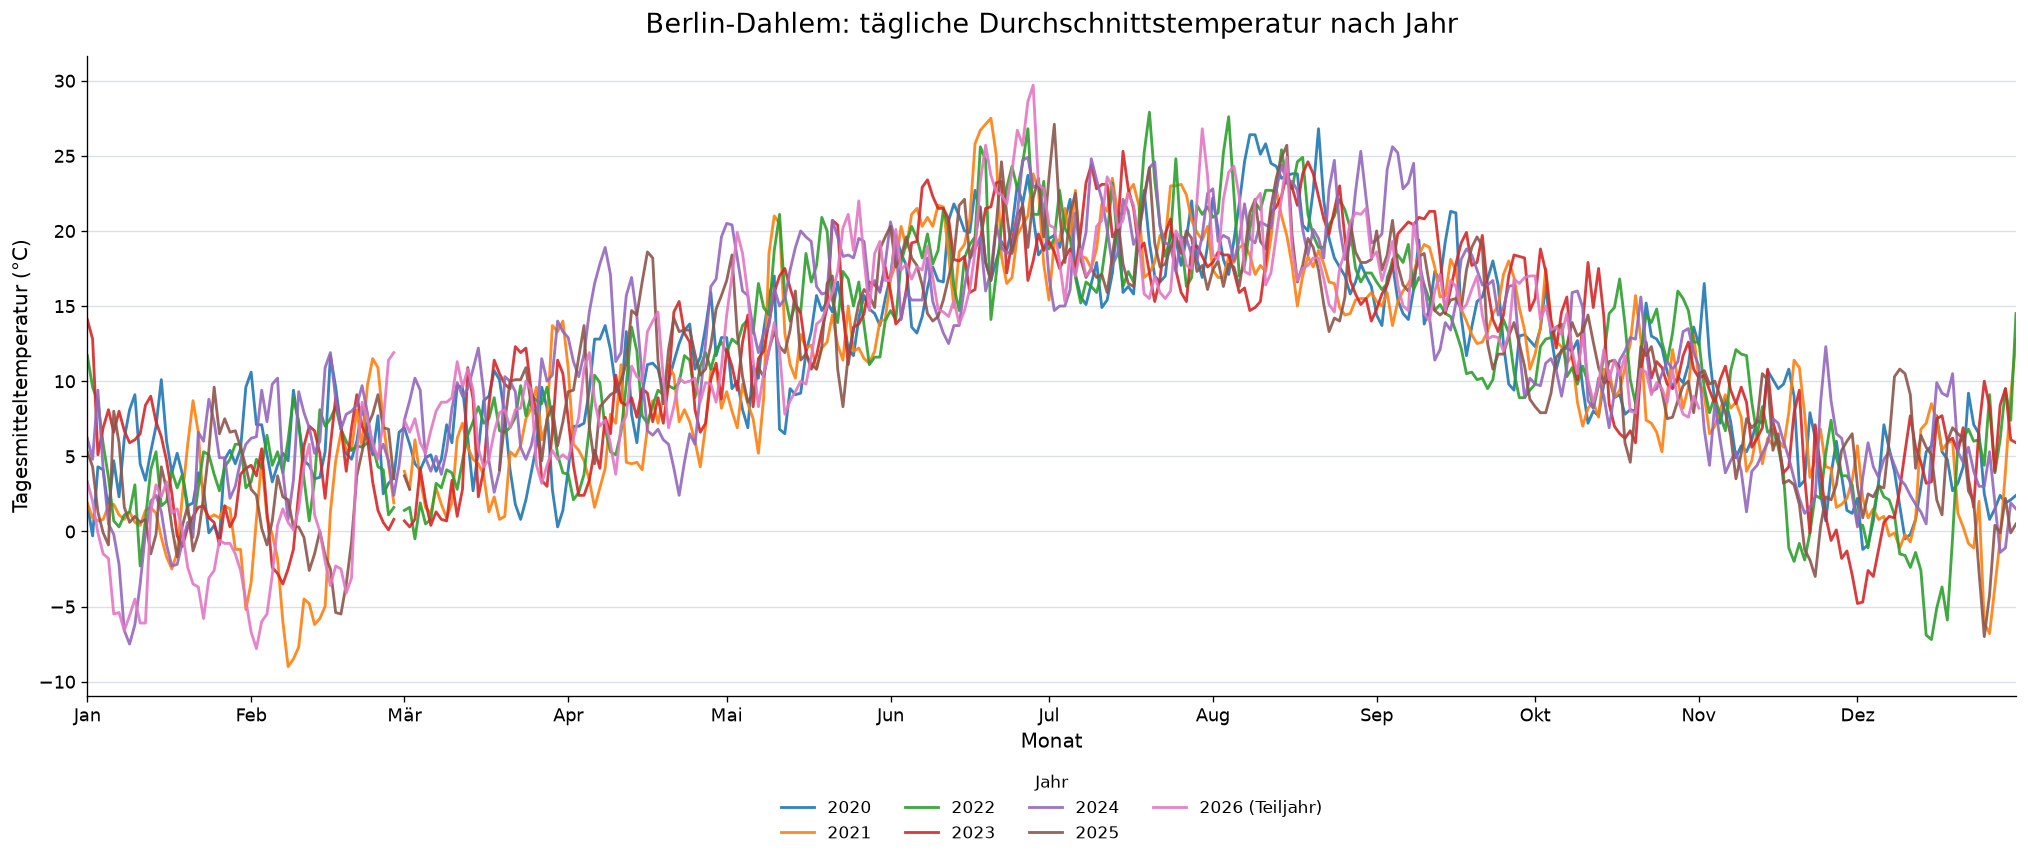

In [8]:
import matplotlib.pyplot as plt
from datetime import date, timedelta

jahreswerte = {}
for eintrag in daten:
    if eintrag["temp_durch_c"]:
        messdatum = date.fromisoformat(eintrag["datum"])
        jahreswerte.setdefault(messdatum.year, {})[
            (messdatum.month, messdatum.day)
        ] = float(eintrag["temp_durch_c"])

kalenderdaten = [date(2000, 1, 1) + timedelta(days=tag) for tag in range(366)]
monate = [date(2000, monat, 1) for monat in range(1, 13)]
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(17, 8), dpi=120)
farben = plt.get_cmap("tab10")
letztes_jahr = max(jahreswerte)

for farbindex, jahr in enumerate(sorted(jahreswerte)):
    werte = [
        jahreswerte[jahr].get((tag.month, tag.day), float("nan"))
        for tag in kalenderdaten
    ]
    label = f"{jahr}"
    if jahr == letztes_jahr and len(jahreswerte[jahr]) < 365:
        label += " (Teiljahr)"
    ax.plot(
        kalenderdaten,
        werte,
        color=farben(farbindex % 10),
        linewidth=1.7,
        alpha=0.9,
        label=label,
    )
    gueltige_werte = list(jahreswerte[jahr].values())
    print(f"{label}: Jahresmittel {sum(gueltige_werte) / len(gueltige_werte):.1f} °C")

ax.set_title("Berlin-Dahlem: tägliche Durchschnittstemperatur nach Jahr", fontsize=16, pad=14)
ax.set_xlabel("Monat", fontsize=12)
ax.set_ylabel("Tagesmitteltemperatur (°C)", fontsize=12)
ax.set_xticks(monate, monatsnamen)
ax.set_xlim(kalenderdaten[0], kalenderdaten[-1])
ax.tick_params(axis="both", labelsize=11)
ax.set_axisbelow(True)
ax.grid(axis="y", color="#d9e1e8", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    title="Jahr",
    ncols=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    frameon=False,
    fontsize=10,
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()
plt.close(fig)
del ax, farben, farbindex, fig, gueltige_werte, jahr, jahreswerte, kalenderdaten, label, letztes_jahr, messdatum, monate, monatsnamen, werte

Winter (Dez–Feb): Mittel 5.39 °C, Median 4.90 °C, n = 601
Sommer (Jun–Aug): Mittel 11.47 °C, Median 11.20 °C, n = 644
Unterschied der Mittelwerte: -53.0 % (Winter gegenüber Sommer)


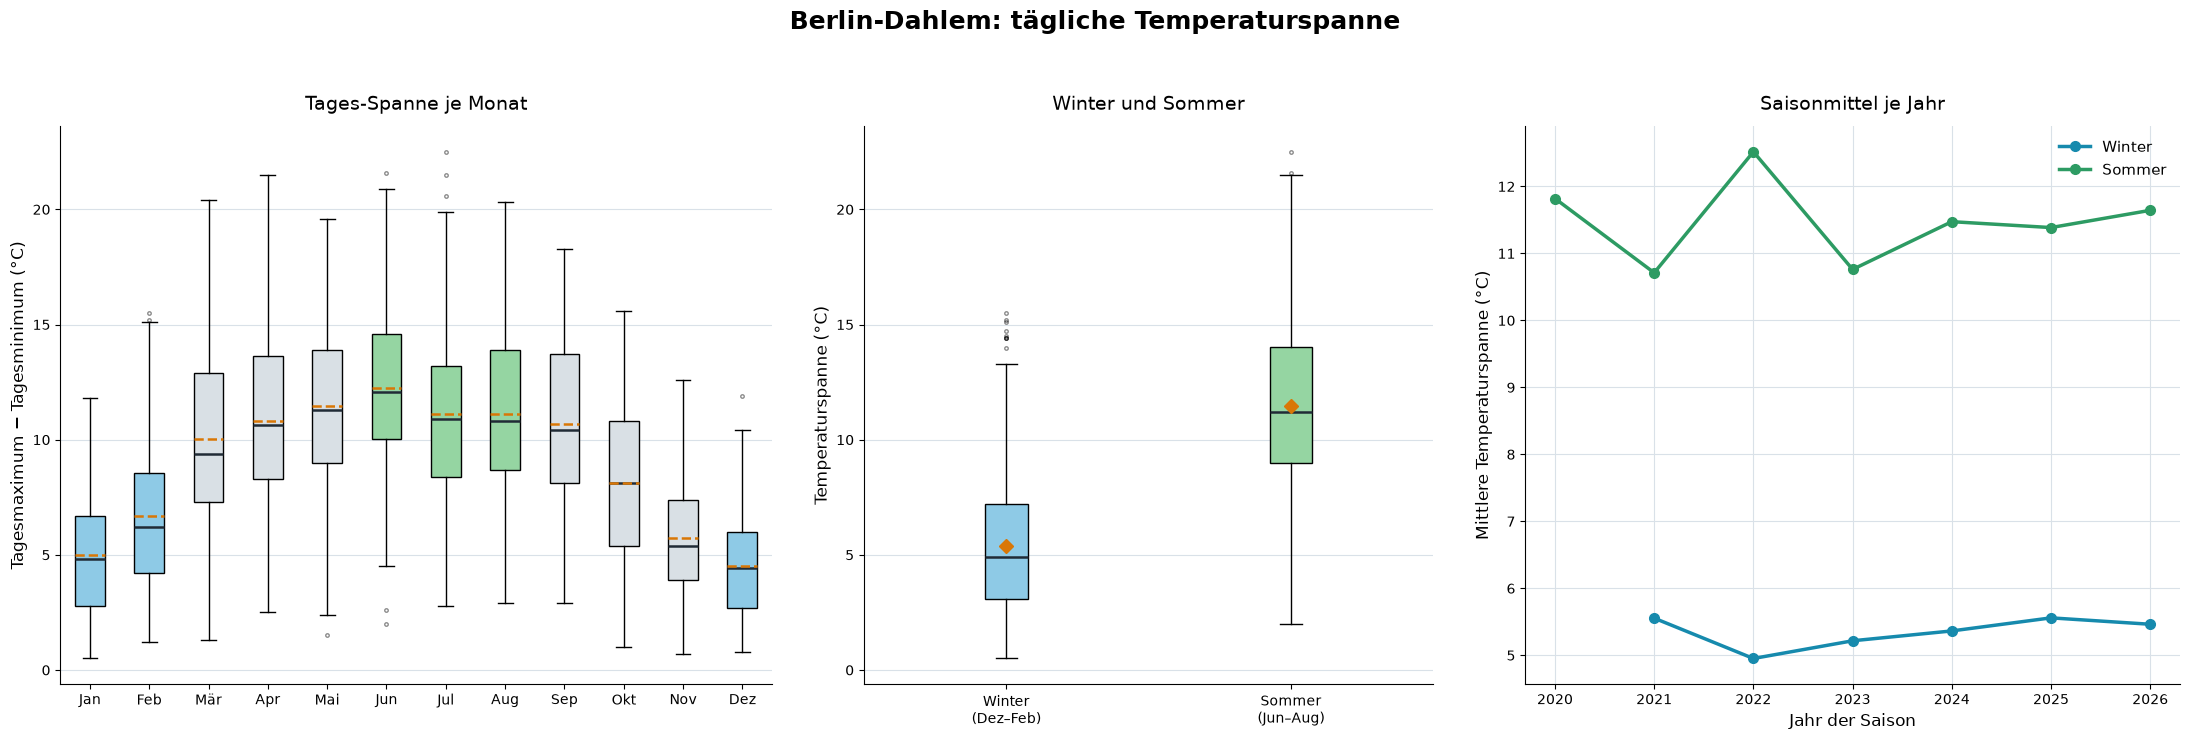

In [9]:
# Tages-Spanne = Tagesmaximum - Tagesminimum
monats_spannen = [[] for _ in range(12)]
winter_spannen = []
sommer_spannen = []
winter_nach_jahr = {}
sommer_nach_jahr = {}
winter_monate_nach_jahr = {}
sommer_monate_nach_jahr = {}

for eintrag in daten:
    if not eintrag["temp_min_c"] or not eintrag["temp_max_c"]:
        continue

    messdatum = date.fromisoformat(eintrag["datum"])
    spanne = float(eintrag["temp_max_c"]) - float(eintrag["temp_min_c"])
    monats_spannen[messdatum.month - 1].append(spanne)

    if messdatum.month in (12, 1, 2):
        winter_spannen.append(spanne)
        saisonjahr = messdatum.year + (1 if messdatum.month == 12 else 0)
        winter_nach_jahr.setdefault(saisonjahr, []).append(spanne)
        winter_monate_nach_jahr.setdefault(saisonjahr, set()).add(messdatum.month)
    elif messdatum.month in (6, 7, 8):
        sommer_spannen.append(spanne)
        sommer_nach_jahr.setdefault(messdatum.year, []).append(spanne)
        sommer_monate_nach_jahr.setdefault(messdatum.year, set()).add(messdatum.month)

monatsnamen_de = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
                  "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

def mittelwert(werte):
    return sum(werte) / len(werte) if werte else float("nan")

winter_mittel = mittelwert(winter_spannen)
sommer_mittel = mittelwert(sommer_spannen)
unterschied_prozent = (winter_mittel / sommer_mittel - 1) * 100

print(f"Winter (Dez–Feb): Mittel {winter_mittel:.2f} °C, "
      f"Median {sorted(winter_spannen)[len(winter_spannen)//2]:.2f} °C, "
      f"n = {len(winter_spannen)}")
print(f"Sommer (Jun–Aug): Mittel {sommer_mittel:.2f} °C, "
      f"Median {sorted(sommer_spannen)[len(sommer_spannen)//2]:.2f} °C, "
      f"n = {len(sommer_spannen)}")
print(f"Unterschied der Mittelwerte: {unterschied_prozent:+.1f} % "
      "(Winter gegenüber Sommer)")

fig, achsen = plt.subplots(
    1,
    3,
    figsize=(22, 7.5),
    gridspec_kw={"width_ratios": [1.25, 1, 1.15]},
)

# Verteilung in jedem Monat
monatliche_daten = [werte for werte in monats_spannen if werte]
monatliche_positionen = [i + 1 for i, werte in enumerate(monats_spannen) if werte]
box_monat = achsen[0].boxplot(
    monatliche_daten,
    positions=monatliche_positionen,
    patch_artist=True,
    showmeans=True,
    meanline=True,
    meanprops={"color": "#d97706", "linewidth": 1.8},
    medianprops={"color": "#202b36", "linewidth": 1.8},
    flierprops={"markersize": 2.5, "alpha": 0.45},
)
for position, box in zip(monatliche_positionen, box_monat["boxes"]):
    box.set_facecolor("#8ecae6" if position in (12, 1, 2) else
                      "#95d5a2" if position in (6, 7, 8) else "#d9e0e5")
achsen[0].set_xticks(range(1, 13), monatsnamen_de)
achsen[0].set_title("Tages-Spanne je Monat", fontsize=14, pad=12)
achsen[0].set_ylabel("Tagesmaximum − Tagesminimum (°C)", fontsize=12)
achsen[0].grid(axis="y", color="#d9e1e8", linewidth=0.8)

# Winter-Sommer-Verteilung
box_saison = achsen[1].boxplot(
    [winter_spannen, sommer_spannen],
    tick_labels=["Winter\n(Dez–Feb)", "Sommer\n(Jun–Aug)"],
    patch_artist=True,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "#d97706", "markeredgecolor": "#d97706", "markersize": 7},
    medianprops={"color": "#202b36", "linewidth": 1.8},
    flierprops={"markersize": 2.5, "alpha": 0.45},
)
for box, farbe in zip(box_saison["boxes"], ["#8ecae6", "#95d5a2"]):
    box.set_facecolor(farbe)
achsen[1].set_title("Winter und Sommer", fontsize=14, pad=12)
achsen[1].set_ylabel("Temperaturspanne (°C)", fontsize=12)
achsen[1].grid(axis="y", color="#d9e1e8", linewidth=0.8)

# Jahresmittel: nur vollständige Saisons mit allen drei Monaten
winter_jahre = sorted(
    jahr for jahr, monate in winter_monate_nach_jahr.items()
    if monate == {12, 1, 2}
)
sommer_jahre = sorted(
    jahr for jahr, monate in sommer_monate_nach_jahr.items()
    if monate == {6, 7, 8}
)

achsen[2].plot(
    winter_jahre,
    [mittelwert(winter_nach_jahr[jahr]) for jahr in winter_jahre],
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="Winter",
    color="#168aad",
)
achsen[2].plot(
    sommer_jahre,
    [mittelwert(sommer_nach_jahr[jahr]) for jahr in sommer_jahre],
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="Sommer",
    color="#2d9b63",
)
achsen[2].set_title("Saisonmittel je Jahr", fontsize=14, pad=12)
achsen[2].set_xlabel("Jahr der Saison", fontsize=12)
achsen[2].set_ylabel("Mittlere Temperaturspanne (°C)", fontsize=12)
achsen[2].grid(color="#d9e1e8", linewidth=0.8)
achsen[2].legend(frameon=False, fontsize=11)

for achse in achsen:
    achse.tick_params(axis="both", labelsize=10)
    achse.set_axisbelow(True)
    achse.spines[["top", "right"]].set_visible(False)

fig.suptitle("Berlin-Dahlem: tägliche Temperaturspanne", fontsize=18, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94), w_pad=3.0)
plt.show()
plt.close(fig)

# Typische Phasen einer Datenanalyse

## 1. Problemformulierung
- Analyseziel und Forschungsfrage präzisieren
- Zielgrößen operationalisieren, zum Beispiel die tägliche Temperaturspanne als Tagesmaximum minus Tagesminimum
- Grundgesamtheit, Zeitraum, Annahmen und Erfolgskriterien festlegen

## 2. Datenakquisition und Datenimport
- Geeignete Datenquellen auswählen und Herkunft dokumentieren
- Daten aus CSV, Datenbanken, APIs oder anderen Quellen importieren
- Datenstruktur, Variablen und Beobachtungseinheiten erfassen

## 3. Datenvalidierung und Datenqualität
- Datentypen, Einheiten, Wertebereiche und Zeitstempel prüfen
- Fehlende Werte, Duplikate und inkonsistente Einträge identifizieren
- Messqualität und Abdeckung der Datenquelle bewerten

## 4. Explorative Datenanalyse (EDA)
- Deskriptive Statistiken wie Mittelwert, Median, Quartile und Streuung berechnen
- Verteilungen, saisonale Muster, Zusammenhänge und Ausreißer untersuchen
- Erste Visualisierungen erstellen, ohne vorschnell kausale Schlüsse zu ziehen

## 5. Datenaufbereitung und Feature Engineering
- Daten filtern, bereinigen und in ein geeignetes Analyseformat transformieren
- Neue Variablen ableiten, etwa Monat, Jahreszeit oder Temperaturspanne
- Fehlwerte transparent behandeln und Transformationen dokumentieren

## 6. Statistische Analyse und Modellierung
- Forschungsfrage mit geeigneten Kennzahlen und statistischen Verfahren beantworten
- Bei Bedarf Hypothesentests, Konfidenzintervalle oder Regressionsmodelle einsetzen
- Modellannahmen und Grenzen der Methode berücksichtigen

## 7. Validierung und Robustheitsprüfung
- Ergebnisse auf Plausibilität und Sensitivität gegenüber Annahmen prüfen
- Vergleichsgruppen und Zeiträume konsistent definieren
- Bei prädiktiven Modellen geeignete Testdaten oder Kreuzvalidierung verwenden

## 8. Interpretation und Kommunikation
- Kennzahlen und Diagramme im fachlichen Kontext interpretieren
- Unsicherheit, Einschränkungen und mögliche Verzerrungen benennen
- Hauptaussagen zielgruppengerecht in Bericht, Präsentation oder Dashboard vermitteln

## 9. Reproduzierbarkeit und Iteration
- Datenstand, Code, Parameter und Softwareumgebung festhalten
- Analyse so dokumentieren, dass sie erneut ausgeführt werden kann
- Feedback und neue Erkenntnisse für weitere Analyseschritte nutzen

## Bezug zu diesem Wetter-Notebook
- **Fragestellung:** Unterscheidet sich die tägliche Temperaturspanne zwischen Winter und Sommer?
- **Operationalisierung:** `temp_max_c - temp_min_c`
- **Gruppierung:** Winter (Dezember bis Februar) und Sommer (Juni bis August)
- **EDA und Visualisierung:** Monatsverteilungen, saisonaler Boxplot und Jahresverläufe

# Prognose der Tagesdurchschnittstemperatur

Ziel ist eine **Ein-Tages-Prognose**: Für einen Tag *t* schätzen MLP und Random Forest die DWD-Tagesmitteltemperatur aus den fünf vorhergehenden Tagen. Als Wettermerkmale dienen Minimum, Maximum, Tagesmittel, Sonnenstunden und Niederschlag; dazu kommen Kalendertag und zyklische Jahresmerkmale.

## Datenstruktur und Zielvariable

- **Eingangsmerkmale:** fünf Wettergrößen für jeden der fünf Vortage (25 Werte) plus `tag_im_jahr`, Sinus und Kosinus (3 Werte), insgesamt 28 Eingänge.
- **Zielvariable:** `temp_durch_c` des Zieltags in °C.
- **Fehlende Werte:** Nur Beispiele mit fünf vollständigen, aufeinanderfolgenden Tagen und gültiger Zieltemperatur werden verwendet. Der 29. Februar wird als Zieltag ausgelassen; nachfolgende Kalendertage werden auf eine 365-Tage-Skala abgebildet.

## Zeitliche Aufteilung

- **Training 2020–2023:** Modelle lernen aus diesen historischen Beispielen.
- **Validierung 2024:** Auswahl der Modellparameter, getrennt für MLP und Random Forest.
- **Test 2025–2026:** identische, unangetastete Zieltage für beide Modelle.

Die chronologische Aufteilung verhindert, dass spätere Beobachtungen in das Training gelangen. Beide Modelle nutzen dieselbe Eingabematrix und dieselben Testtage, damit die Kennzahlen vergleichbar sind.

## Modelle und Bewertung

Verglichen werden ein standardisiertes **MLP-Regressionsmodell** und ein **Random-Forest-Regressor**. Beide erhalten dieselben 28 Merkmale. MLP-Eingänge werden standardisiert; ein Random Forest benötigt diese Skalierung nicht. MAE und RMSE werden in °C angegeben; zusätzlich dient „morgen = heute“ als Persistenz-Baseline.

## 1. Überwachtes Lernproblem und Feature Engineering

Die **Designmatrix** `X` enthält pro Beispiel die fünf Wettergrößen `temp_min_c`, `temp_max_c`, `temp_durch_c`, `sonnenstunden_h` und `niederschlagsmenge_mm` für jeden der fünf aufeinanderfolgenden Vortage. Dazu kommen der auf 365 Tage normierte Kalendertag sowie Sinus und Kosinus dieses Jahreszyklus. Das ergibt 28 Eingangsmerkmale. `y` enthält die Tagesmitteltemperatur des Zieltags.

Es werden nur vollständige Fünf-Tage-Fenster verwendet. Die Wetterwerte sind vom ältesten bis zum jüngsten Vortag angeordnet. Beide Modelle erhalten danach exakt dieselben Trainings-, Validierungs- und Testbeispiele.

In [14]:
import calendar
from datetime import date, timedelta
from math import cos, pi, sin

import numpy as np

wetter_spalten = [
    "temp_min_c",
    "temp_max_c",
    "temp_durch_c",
    "sonnenstunden_h",
    "niederschlagsmenge_mm",
]
wetter_bezeichnungen = {
    "temp_min_c": "Minimum",
    "temp_max_c": "Maximum",
    "temp_durch_c": "Tagesmittel",
    "sonnenstunden_h": "Sonnenstunden",
    "niederschlagsmenge_mm": "Niederschlag",
}
wetter_nach_datum = {}
for eintrag in daten:
    messdatum = date.fromisoformat(eintrag["datum"])
    wetter_nach_datum[messdatum] = {
        spalte: float(eintrag[spalte]) if eintrag[spalte] else float("nan")
        for spalte in wetter_spalten
    }

daten_daten_wetter = sorted(wetter_nach_datum)
merkmal_namen_wetter = [
    f"{wetter_bezeichnungen[spalte]}_t-{abstand}"
    for abstand in range(5, 0, -1)
    for spalte in wetter_spalten
] + ["tag_im_jahr", "jahres_sinus", "jahres_cosinus"]
X_wetter_liste = []
y_wetter_liste = []
termine_wetter_liste = []

for index, zieltag in enumerate(daten_daten_wetter):
    if zieltag.month == 2 and zieltag.day == 29:
        continue

    vergangene_tage = [zieltag - timedelta(days=abstand) for abstand in range(5, 0, -1)]
    if index < 5 or daten_daten_wetter[index - 5:index] != vergangene_tage:
        continue

    vergangene_wetterwerte = [
        wetter_nach_datum[tag][spalte]
        for tag in vergangene_tage
        for spalte in wetter_spalten
    ]
    zieltemperatur = wetter_nach_datum[zieltag]["temp_durch_c"]
    if not all(np.isfinite(vergangene_wetterwerte)) or not np.isfinite(zieltemperatur):
        continue

    tag_im_jahr = zieltag.timetuple().tm_yday
    if calendar.isleap(zieltag.year) and zieltag.month > 2:
        tag_im_jahr -= 1
    jahreswinkel = 2 * pi * (tag_im_jahr - 1) / 365

    X_wetter_liste.append(
        vergangene_wetterwerte
        + [tag_im_jahr, sin(jahreswinkel), cos(jahreswinkel)]
    )
    y_wetter_liste.append(zieltemperatur)
    termine_wetter_liste.append(zieltag)

X_wetter = np.asarray(X_wetter_liste, dtype=float)
y_wetter = np.asarray(y_wetter_liste, dtype=float)
jahre_wetter = np.asarray([tag.year for tag in termine_wetter_liste])

train_maske_wetter = jahre_wetter <= 2023
validierungs_maske_wetter = jahre_wetter == 2024
test_maske_wetter = jahre_wetter >= 2025

X_wetter_train = X_wetter[train_maske_wetter]
y_wetter_train = y_wetter[train_maske_wetter]
X_wetter_validierung = X_wetter[validierungs_maske_wetter]
y_wetter_validierung = y_wetter[validierungs_maske_wetter]
X_wetter_test = X_wetter[test_maske_wetter]
y_wetter_test = y_wetter[test_maske_wetter]
termine_wetter_test = np.asarray(termine_wetter_liste, dtype=object)[test_maske_wetter]

print(f"Vollständige Beispiele mit allen Wettermerkmalen: {len(X_wetter)}")
print(f"Eingangsform: {X_wetter.shape}; Merkmale: {len(merkmal_namen_wetter)}")
print(f"Training 2020–2023: {len(X_wetter_train)}")
print(f"Validierung 2024: {len(X_wetter_validierung)}")
print(f"Test 2025–2026: {len(X_wetter_test)}")
print(f"Erster Zieltag: {termine_wetter_liste[0]}; letzter Zieltag: {termine_wetter_liste[-1]}")
print("Merkmale:", merkmal_namen_wetter)
print("Beispiel X:", X_wetter[0])
print(f"Beispiel y: {y_wetter[0]:.1f} °C am {termine_wetter_liste[0]}")

Vollständige Beispiele mit allen Wettermerkmalen: 2469
Eingangsform: (2469, 28); Merkmale: 28
Training 2020–2023: 1455
Validierung 2024: 365
Test 2025–2026: 649
Erster Zieltag: 2020-01-06; letzter Zieltag: 2026-11-01
Merkmale: ['Minimum_t-5', 'Maximum_t-5', 'Tagesmittel_t-5', 'Sonnenstunden_t-5', 'Niederschlag_t-5', 'Minimum_t-4', 'Maximum_t-4', 'Tagesmittel_t-4', 'Sonnenstunden_t-4', 'Niederschlag_t-4', 'Minimum_t-3', 'Maximum_t-3', 'Tagesmittel_t-3', 'Sonnenstunden_t-3', 'Niederschlag_t-3', 'Minimum_t-2', 'Maximum_t-2', 'Tagesmittel_t-2', 'Sonnenstunden_t-2', 'Niederschlag_t-2', 'Minimum_t-1', 'Maximum_t-1', 'Tagesmittel_t-1', 'Sonnenstunden_t-1', 'Niederschlag_t-1', 'tag_im_jahr', 'jahres_sinus', 'jahres_cosinus']
Beispiel X: [-2.8         5.          1.8         2.9         0.         -4.1
  6.2        -0.3         7.5         0.          0.8         6.9
  4.3         0.          4.4         1.7         5.6         4.1
  0.          3.         -1.4         3.6         1.4         2

## 2. MLP trainieren und Modellparameter auswählen

Das **MLP** ist ein neuronales Netz für Regression. Es lernt eine nichtlineare Abbildung der 28 gemeinsamen Eingangsmerkmale auf die Tagesmitteltemperatur. Ein `StandardScaler` standardisiert die Merkmale und wird nur auf Trainingsdaten angepasst.

Die Regularisierung `alpha` wird anhand des MAE 2024 ausgewählt. Anschließend wird das MLP auf Training plus Validierung neu trainiert. Der Random Forest wird im nächsten Schritt mit denselben Datenaufteilungen und Merkmalen trainiert; seine Baumtiefe und Mindestblattgröße werden ebenfalls anhand 2024 gewählt. Die Testjahre bleiben bis zum Modellvergleich unangetastet.

In [15]:
from sklearn.metrics import mean_absolute_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alpha_kandidaten = [0.001, 0.01, 0.1, 1.0]
mlp_validierungs_mae = {}

for alpha in alpha_kandidaten:
    kandidat_mlp = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            solver="adam",
            alpha=alpha,
            learning_rate_init=0.003,
            max_iter=1500,
            random_state=42,
        ),
    )
    kandidat_mlp.fit(X_wetter_train, y_wetter_train)
    prognose_mlp_validierung = kandidat_mlp.predict(X_wetter_validierung)
    mlp_validierungs_mae[alpha] = mean_absolute_error(
        y_wetter_validierung, prognose_mlp_validierung
    )
    print(f"MLP alpha={alpha:g}: Validierungs-MAE {mlp_validierungs_mae[alpha]:.3f} °C")

bestes_alpha_mlp = min(mlp_validierungs_mae, key=mlp_validierungs_mae.get)
print(f"Ausgewähltes MLP-alpha: {bestes_alpha_mlp:g}")

X_wetter_train_final = np.concatenate([X_wetter_train, X_wetter_validierung])
y_wetter_train_final = np.concatenate([y_wetter_train, y_wetter_validierung])

modell_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=bestes_alpha_mlp,
        learning_rate_init=0.003,
        max_iter=1500,
        random_state=42,
    ),
)
modell_mlp.fit(X_wetter_train_final, y_wetter_train_final)
print(f"Finales MLP mit {len(y_wetter_train_final)} Beispielen trainiert.")

MLP alpha=0.001: Validierungs-MAE 1.846 °C
MLP alpha=0.01: Validierungs-MAE 1.844 °C
MLP alpha=0.1: Validierungs-MAE 1.838 °C
MLP alpha=1: Validierungs-MAE 1.799 °C
Ausgewähltes MLP-alpha: 1
Finales MLP mit 1820 Beispielen trainiert.


## 3. Random Forest trainieren und Modellparameter auswählen

Der **Random Forest Regressor** mittelt die Vorhersagen vieler Entscheidungsbäume. Anders als das MLP benötigt er keine Standardisierung. Um Überanpassung zu begrenzen, vergleichen wir verschiedene Kombinationen aus maximaler Baumtiefe und Mindestgröße eines Blatts. Die Auswahl erfolgt wieder ausschließlich anhand des MAE 2024; anschließend wird der gewählte Forest auf Training plus Validierung neu trainiert.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_kandidaten = [
    {"max_depth": 6, "min_samples_leaf": 3},
    {"max_depth": 10, "min_samples_leaf": 3},
    {"max_depth": 16, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 3},
]
rf_validierungs_mae = {}

for parameter in rf_kandidaten:
    kandidat_rf = RandomForestRegressor(
        n_estimators=300,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
        **parameter,
    )
    kandidat_rf.fit(X_wetter_train, y_wetter_train)
    prognose_rf_validierung = kandidat_rf.predict(X_wetter_validierung)
    schluessel = (parameter["max_depth"], parameter["min_samples_leaf"])
    rf_validierungs_mae[schluessel] = mean_absolute_error(
        y_wetter_validierung, prognose_rf_validierung
    )
    print(
        f"Random Forest Tiefe={parameter['max_depth']}, "
        f"Blatt={parameter['min_samples_leaf']}: "
        f"Validierungs-MAE {rf_validierungs_mae[schluessel]:.3f} °C"
    )

bester_rf_schluessel = min(rf_validierungs_mae, key=rf_validierungs_mae.get)
bestes_rf_parameter = {
    "max_depth": bester_rf_schluessel[0],
    "min_samples_leaf": bester_rf_schluessel[1],
}
print(f"Ausgewählte Random-Forest-Parameter: {bestes_rf_parameter}")

modell_rf = RandomForestRegressor(
    n_estimators=300,
    max_features=0.8,
    random_state=42,
    n_jobs=-1,
    **bestes_rf_parameter,
)
modell_rf.fit(X_wetter_train_final, y_wetter_train_final)
print(f"Finaler Random Forest mit {len(y_wetter_train_final)} Beispielen trainiert.")

Random Forest Tiefe=6, Blatt=3: Validierungs-MAE 1.646 °C
Random Forest Tiefe=10, Blatt=3: Validierungs-MAE 1.629 °C


## 3. Testdaten auswerten

Erst jetzt wird das finale Modell auf den zuvor zurückgehaltenen Tagen 2025–2026 geprüft. **MAE** ist der durchschnittliche absolute Prognosefehler, **RMSE** gewichtet größere Fehler stärker und **R²** beschreibt, wie viel Streuung gegenüber dem Mittelwert erklärt wird. Als Referenz dient die Persistenzprognose `morgen = heute`. Ein niedrigerer MAE/RMSE als bei dieser Referenz spricht für einen Mehrwert des Modells.

Testzeitraum: 2025-01-01 bis 2026-11-01
Testtage: 649
MLP MAE: 1.58 °C
MLP RMSE: 2.00 °C
MLP R²: 0.930
Persistenz-Baseline MAE: 1.73 °C
Persistenz-Baseline RMSE: 2.23 °C
MAE-Änderung gegenüber Baseline: +8.8 %


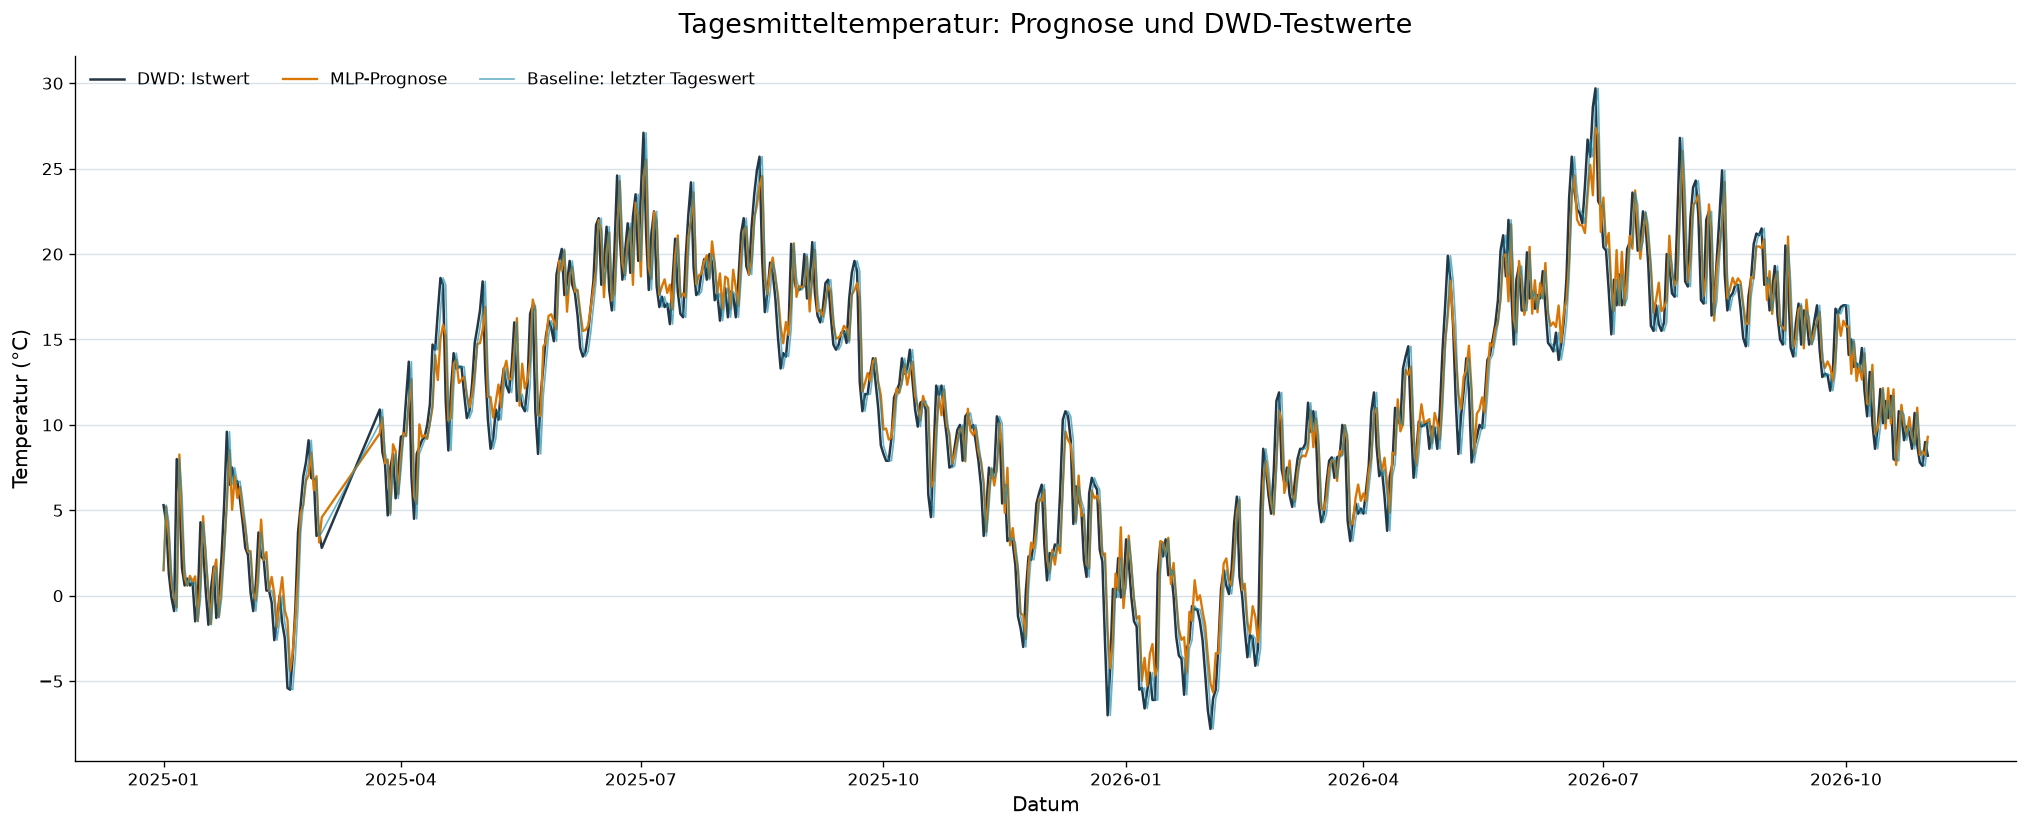

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

prognose_test = modell.predict(X_test)
persistenz_test = X_test[:, 4]

mae_mlp = mean_absolute_error(y_test, prognose_test)
rmse_mlp = np.sqrt(mean_squared_error(y_test, prognose_test))
r2_mlp = r2_score(y_test, prognose_test)
mae_persistenz = mean_absolute_error(y_test, persistenz_test)
rmse_persistenz = np.sqrt(mean_squared_error(y_test, persistenz_test))
mae_verbesserung = 100 * (1 - mae_mlp / mae_persistenz)

print(f"Testzeitraum: {termine_test[0]} bis {termine_test[-1]}")
print(f"Testtage: {len(y_test)}")
print(f"MLP MAE: {mae_mlp:.2f} °C")
print(f"MLP RMSE: {rmse_mlp:.2f} °C")
print(f"MLP R²: {r2_mlp:.3f}")
print(f"Persistenz-Baseline MAE: {mae_persistenz:.2f} °C")
print(f"Persistenz-Baseline RMSE: {rmse_persistenz:.2f} °C")
print(f"MAE-Änderung gegenüber Baseline: {mae_verbesserung:+.1f} %")

fig, ax = plt.subplots(figsize=(17, 7), dpi=120)
ax.plot(termine_test, y_test, color="#253746", linewidth=1.5, label="DWD: Istwert")
ax.plot(termine_test, prognose_test, color="#d97706", linewidth=1.4, label="MLP-Prognose")
ax.plot(
    termine_test,
    persistenz_test,
    color="#168aad",
    linewidth=1.0,
    alpha=0.65,
    label="Baseline: letzter Tageswert",
)
ax.set_title("Tagesmitteltemperatur: Prognose und DWD-Testwerte", fontsize=16, pad=14)
ax.set_xlabel("Datum", fontsize=12)
ax.set_ylabel("Temperatur (°C)", fontsize=12)
ax.tick_params(axis="both", labelsize=10)
ax.grid(axis="y", color="#d9e1e8", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncols=3)
fig.tight_layout()
plt.show()
plt.close(fig)

## Einordnung der Testgüte

Im aktuellen Testzeitraum **01.01.2025 bis 01.11.2026** wurden 649 Tage geprüft. Das MLP erreicht **MAE 1,58 °C**, **RMSE 2,00 °C** und **R² 0,930**. Die Persistenz-Baseline erreicht **MAE 1,73 °C** und **RMSE 2,23 °C**. Der mittlere absolute Fehler sinkt damit um rund **8,8 %** gegenüber „morgen = heute“.

Der MAE bedeutet: Die Vorhersage weicht im Test durchschnittlich um etwa 1,58 °C ab. R² ist kein Genauigkeits-Prozentsatz. Der Vorteil gegenüber der sehr einfachen Baseline ist vorhanden, aber begrenzt. Das ist ein **rollierender Ein-Tages-Test**: Für jeden Testtag werden die fünf tatsächlich beobachteten Vortageswerte verwendet. Das ist keine mehrtägige Prognose ohne neue Messungen. Das Modell nutzt außerdem keine Wettervorhersagen oder weiteren meteorologischen Variablen und kann plötzliche Wetterumschwünge daher nur begrenzt erfassen.

## 4. Nächsten Tag prognostizieren

Nach der unabhängigen Testauswertung wird eine Einsatzversion mit allen verfügbaren Trainingsbeispielen bis zum letzten DWD-Tag trainiert. Für die Prognose verwendet sie die fünf letzten beobachteten Tagesmittelwerte und den Kalendertag des Folgetags. Das Ergebnis ist eine Modellschätzung, keine amtliche DWD-Vorhersage.

In [6]:
import calendar
from datetime import timedelta

# Für den konkreten nächsten Tag wird das Modell nach der Testauswertung
# mit allen verfügbaren Beispielen neu trainiert.
modell_prognose = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=bestes_alpha,
        learning_rate_init=0.003,
        max_iter=1500,
        random_state=42,
    ),
)
modell_prognose.fit(X, y)

letzter_dwd_tag = max(temperatur_nach_datum)
letzte_fuenf_tage = [
    letzter_dwd_tag - timedelta(days=abstand)
    for abstand in range(4, -1, -1)
]
letzte_fuenf_temperaturen = [
    temperatur_nach_datum[tag] for tag in letzte_fuenf_tage
]
if not all(np.isfinite(letzte_fuenf_temperaturen)):
    raise ValueError("Für die letzten fünf Tage fehlen DWD-Tagesmittelwerte.")

prognose_datum = letzter_dwd_tag + timedelta(days=1)
tag_im_jahr_prognose = prognose_datum.timetuple().tm_yday
if calendar.isleap(prognose_datum.year) and prognose_datum.month > 2:
    tag_im_jahr_prognose -= 1
prognose_winkel = 2 * pi * (tag_im_jahr_prognose - 1) / 365
X_naechster_tag = np.asarray(
    [
        letzte_fuenf_temperaturen
        + [
            tag_im_jahr_prognose,
            sin(prognose_winkel),
            cos(prognose_winkel),
        ]
    ],
    dtype=float,
)
prognose_naechster_tag = modell_prognose.predict(X_naechster_tag)[0]

print(f"Letzter DWD-Datentag: {letzter_dwd_tag}")
print(f"Eingangs-Tagesmittel: {[round(wert, 1) for wert in letzte_fuenf_temperaturen]} °C")
print(f"Modellprognose für {prognose_datum}: {prognose_naechster_tag:.1f} °C")

Letzter DWD-Datentag: 2026-11-01
Eingangs-Tagesmittel: [8.8, 7.8, 7.6, 9.0, 8.2] °C
Modellprognose für 2026-11-02: 7.9 °C
